# Ensamblaje de una cápside con N = 12 subunidades

Este notebook simula el ensamblaje de un modelo dodecaédrico (N = 12) a partir de la ecuación maestra cinética (*kinetic master equation*), que describe la evolución temporal de las subunidades de la cápside. Se usa N = 12 para reproducir el caso estudiado por Zlotnick.

Referencias en las que se basa el código:

* Hagan, M. F. (2014). Modeling viral capsid assembly. *Advances in Chemical Physics*, 155, 1-68.
* Zlotnick, A. (1994). To build a virus capsid: an equilibrium model of the self assembly of polyhedral protein complexes. *Journal of Molecular Biology*, 241(1), 59-67.
* Endres, D., & Zlotnick, A. (2002). Model-based analysis of assembly kinetics for virus capsids or other spherical polymers. *Biophysical Journal*, 83(2), 1217-1230.

La notación sigue a Hagan (2014) y a Endres y Zlotnick (2002).

# Ecuaciones del modelo

Notación:

* $N$: número de subunidades de la cápside completa.
* $M$: concentración de monómero.
* $I_n$: concentración del intermedio con $n$ subunidades.
* $I_N$: concentración de la cápside completa ($N$ subunidades).
* $f_n$: velocidad de asociación del monómero a un intermedio de tamaño $n$. Se escribe $f_n = s_n^f f$, donde $f$ es la constante de asociación base y $s_n^f$ es el factor estadístico geométrico, que cuenta los sitios disponibles donde puede unirse el monómero.
* $b_n$: velocidad de disociación. Se escribe $b_n = s_n^b b_n^*$, donde $b_n^*$ es la constante de disociación base y $s_n^b$ es el factor estadístico que cuenta las subunidades que pueden separarse de la cápside.
* Hagan (2014) escribe $b_n^* = f\,e^{\Delta G_n^{contacto}/k_B T} = f\,e^{\Delta p\,\epsilon_b}$.
* $\Delta p = p_n - p_{n-1}$: número de contactos nuevos que se forman al pasar de $n-1$ a $n$.
* $\epsilon_b = \Delta G_n^{contacto}/k_B T$: energía libre de un contacto entre proteínas, en unidades de $k_B T$.

Ecuaciones:

* Flujo neto de la transición $n \to n+1$:

  $J_n = f_n I_n M - b_{n+1} I_{n+1}$

* Intermedios, para $1 < n < N$:

  $dI_n/dt = J_{n-1} - J_n$

* Monómero. Al inicio solo hay monómero sin ensamblar ($n = 1$):

  $dM/dt = -2J_1 - \sum_{n=2}^{N-1} J_n$

* Cápside completa. Cuando se completa ($n = N$) el crecimiento se detiene, es decir, $J_N = 0$:

  $dI_N/dt = J_{N-1}$

Parámetros de la simulación:

* `f_base = 1e5`: constante de asociación base, en M⁻¹ s⁻¹.
* `total_monomer_conc = 50e-6`: concentración inicial de monómero, en M.
* $\epsilon_b = -5.0$: energía libre de un contacto entre proteínas, adimensional (en múltiplos de $k_B T$, como en Hagan 2014).
* $\Delta p$: número de contactos nuevos por paso, tomado de la tabla de Zlotnick (1994).
* $s_f$: factor estadístico de asociación (geométrico).
* $s_b$: factor estadístico de disociación.

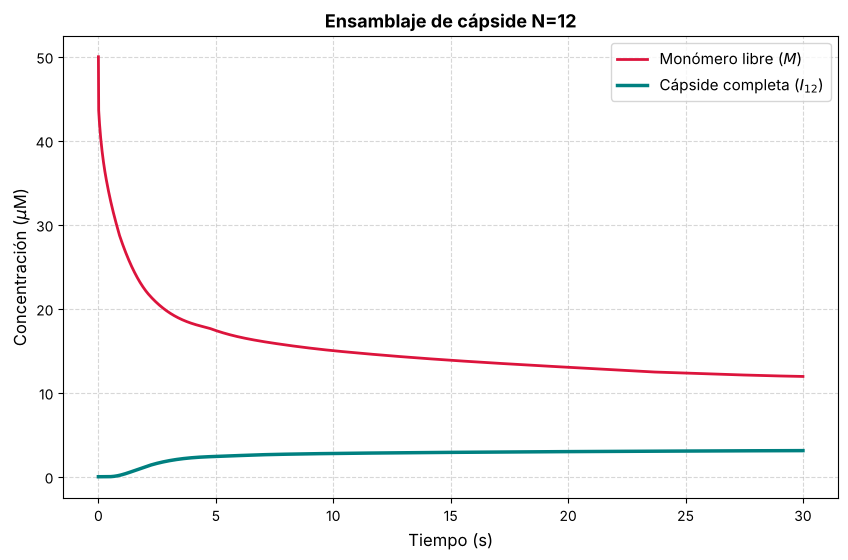

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


# ---- sistema de ecuaciones diferenciales ----------------------------------
def capside_ecuacion(t, y, f, epsilon_b, s_f, s_b, delta_p, N):
    """
    y[0]     = [M]   (monómero)
    y[1:]    = [I_n] (intermedios)
    y[N-1]   = [I_N] (cápside completa)
    dydt     = derivadas de las mismas variables
    b_star   = b* (velocidad de disociación base, en 1/s)
    J[n]     = flujo de la transición n -> n+1
    s_f[n]   = factor estadístico de asociación
    s_b[n]   = factor estadístico de disociación
    """
    dydt = np.zeros(N)


    # velocidad de disociación base b*, en 1/s
    b_star = f * np.exp(delta_p * epsilon_b)

    # Flujo neto: J[n] es el flujo de transicion de n a n+1
    J = np.zeros(N + 1)

    # pasando de n=1 a n=2
    J[1] = (s_f[1] * f * y[0]**2) - (s_b[2] * b_star[2] * y[1])

    # elongación desde n=2 hasta N-1
    for n in range(2, N):
        J[n] = (s_f[n] * f * y[n-1] * y[0]) - (s_b[n+1] * b_star[n+1] * y[n])

    # ecuación del monómero dM/dt
    dydt[0] = -2 * J[1] - np.sum(J[2:N])

    # ecuación de los intermedios dI_n/dt, de n=2 a N-1
    for n in range(2, N):
        i = n - 1  # 0-indexed mapping
        dydt[i] = J[n-1] - J[n]

    # ecuación de la cápside completa dI_N/dt (n=N)
    dydt[N-1] = J[N-1]

    return dydt
#-------------------------------------------------------------------------



# Parámetros de la simulación
# -----------------------------------------------------------------
N = 12                     # número de subunidades de la cápside final
total_monomer_conc = 5e-5  # 50 µM (en M), concentración inicial
f_base = 1e5               # constante de asociación base (1/(M s))

# energía de contacto (en k_B T)
epsilon_b = -5.0

# parámetros geométricos (tabla 1 de Zlotnick 1994); pueden reemplazarse por una función
delta_p = np.array([0, 0, 1, 2, 2, 2, 3, 2, 3, 3, 3, 4, 5])
s_f     = np.array([0, 10, 2, 3, 4, 1, 5, 2, 2, 3, 2, 1, 0])
s_b     = np.array([0, 0, 1, 3, 2, 2, 5, 1, 4, 3, 2, 5, 12])

# condición inicial: solo hay monómero
y = np.zeros(N)
y[0] = total_monomer_conc

# integración de 0 a 30 s, con 2500 puntos de salida
t_rango = (0.0, 30.0)
t = np.linspace(t_rango[0], t_rango[1], 2500)

# solución del sistema de ecuaciones diferenciales
solution = solve_ivp(
    capside_ecuacion,
    t_rango,
    y,
    args=(f_base, epsilon_b, s_f, s_b, delta_p, N),
    t_eval=t,
    method='Radau'
)


# gráficas y resultados
# --------------------------------------
plt.figure(figsize=(10, 6))

# concentraciones en µM
plt.plot(solution.t, solution.y[0] * 1e6, label='Monómero libre ($M$)', color='crimson', lw=2)
#plt.plot(solution.t, solution.y[5] * 1e6, label='Mid-Size Intermediates ($I_6$)#', color='darkorange', linestyle='--')
plt.plot(solution.t, solution.y[N-1] * 1e6, label='Cápside completa ($I_{12}$)', color='teal', lw=2.5)

plt.xlabel('Tiempo (s)', fontsize=12)
plt.ylabel(r'Concentración ($\mu$M)', fontsize=12)
plt.title('Ensamblaje de cápside N=12', fontsize=13, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()